# Feature Engineering

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

from src.python import data_loader
from src.python import feature_engineering 

## 1. Load Processed Dataset


In [15]:
df = data_loader.load_data("../data/processed/cleaned_trajectories.csv")

df.head()

,id,time,xloc_kf,yloc_kf,lane_kf,speed_kf,acceleration_kf,length_smoothed,width_smoothed,type_most_common,acc,run_index
0,143,38.1,1778.595,135.24,-5,23.15,0.0,5.45,2.67,small-vehicle,no,5
1,143,38.2,1780.910,135.60,-5,23.15,-0.5,5.45,2.67,small-vehicle,no,5
2,143,38.3,1783.225,135.97,-5,23.10,1.0,5.45,2.67,small-vehicle,no,5
3,143,38.4,1785.535,136.33,-5,23.20,-1.0,5.45,2.67,small-vehicle,no,5
4,143,38.5,1787.855,136.70,-5,23.10,1.0,5.45,2.67,small-vehicle,no,5



## 2. Speed Transformation



In [20]:
df_features = feature_engineering.add_speed_kmh(df)

df_features[["speed_kf", "speed_kmh"]].head()

,speed_kf,speed_kmh
0,23.15,83.34
1,23.15,83.34
2,23.10,83.16
3,23.20,83.52
4,23.10,83.16


## 3. Jerk Calculation



In [21]:
df_features = feature_engineering.add_jerk(df_features)

df_features[
    ["id", "time", "acceleration_kf", "jerk_mps3"]
].head(10)

,id,time,acceleration_kf,jerk_mps3
0,143,38.1,0.0,NaN
1,143,38.2,-0.5,-5.0
2,143,38.3,1.0,15.0
3,143,38.4,-1.0,-20.0
4,143,38.5,1.0,20.0
5,143,38.6,-1.0,-20.0
6,143,38.7,0.5,15.0
7,143,38.8,-0.5,-10.0
8,143,38.9,0.0,5.0
9,143,39.0,0.0,0.0


## 4. Absolute Acceleration



In [22]:
df_features = feature_engineering.add_absolute_acceleration(df_features)

df_features[
    ["acceleration_kf", "abs_acceleration"]
].head()

,acceleration_kf,abs_acceleration
0,0.0,0.0
1,-0.5,0.5
2,1.0,1.0
3,-1.0,1.0
4,1.0,1.0


## 5. Feature Validation



In [23]:
new_features = [
    "speed_kmh",
    "jerk_mps3",
    "abs_acceleration"
]

df_features[new_features].describe()

,speed_kmh,jerk_mps3,abs_acceleration
count,137928.000000,137216.000000,137928.000000
mean,98.687774,0.003727,0.917312
std,13.528036,21.159341,1.256642
min,53.100000,-260.000000,0.000000
25%,89.100000,-10.000000,0.500000
50%,98.640000,0.000000,0.500000
75%,108.720000,10.000000,1.000000
max,148.860000,260.000000,22.000000


In [24]:
assert "speed_kmh" in df_features.columns
assert "jerk_mps3" in df_features.columns
assert "abs_acceleration" in df_features.columns

assert (df_features["abs_acceleration"] >= 0).all()

print("Feature validation completed.")

Feature validation completed.


## 6. Feature Analysis and Visualization



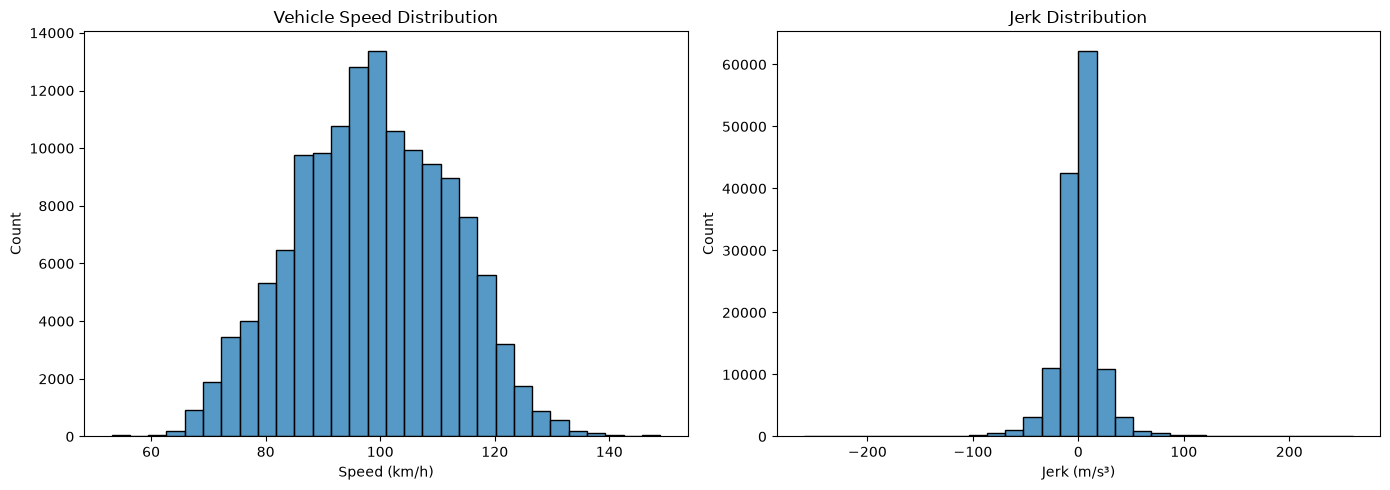

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df_features, x="speed_kmh", bins=30, ax=axes[0])
axes[0].set_title("Vehicle Speed Distribution")
axes[0].set_xlabel("Speed (km/h)")

sns.histplot(data=df_features, x="jerk_mps3", bins=30, ax=axes[1])
axes[1].set_title("Jerk Distribution")
axes[1].set_xlabel("Jerk (m/s³)")

plt.tight_layout()
plt.show()

## 7. Summary

The feature engineering process introduced three additional variables:

- `speed_kmh`: vehicle speed converted to kilometers per hour.
- `jerk_mps3`: rate of change of acceleration over time.
- `abs_acceleration`: absolute magnitude of acceleration.

These features provide additional information about vehicle movement
and will be used in the subsequent scenario detection analysis.